**Estimated time to read:** 10-15 minutes
**Depends on:** Setup and Orientation
**Unlocks:** Precomputed Tracking, Results and Analysis

In this page we explore real mouse behavioral data, read it with community-standard tools, and build intuition for what pose data looks like before we do any modeling. We will load, inspect, and visualize pose files generated from the Kumar Lab's [mouse-tracking-runtime](https://github.com/KumarLabJax/mouse-tracking-runtime) pipeline.


## Learning Goals

By the end of this page, you should be able to:

- Explain what a JABS pose-estimation (HDF5) file contains, including what `points` and `confidence` represent
- Read pose data into a tidy table, correctly accounting for the `[y, x]` coordinate order and the animal axis
- Visualize keypoint trajectories and a single-frame skeleton, and use them as a sanity check on pose quality
- Identify which body parts are consistently harder to track and explain why


## Scientific Context

This module works with the **JABS Behavior Classifier Example Projects**, a curated set of annotated behavioral sessions published on Zenodo:

> Geuther, B., Beane, M., Kumar, V., Choudhary, A. "JABS Behavior Classifier Example Projects." Zenodo, 2025. https://doi.org/10.5281/zenodo.16697331

**License:** CC BY-NC 4.0

The deposit contains several annotation projects - grooming, turn, and single-mouse behaviors. This module uses the **grooming** project as its running example. Grooming is a well-defined, visually legible behavior: a mouse manipulates its face and coat in a characteristic coordinated sequence. It is densely annotated across 25 sessions, making it a good fit for training an active-learning classifier with modest labeled data.

Each session in the grooming project is a 5-minute (9,000-frame at 30 fps) clip paired with:
- a `.avi` video
- a `*_pose_est_v6.h5` pose estimation file
- behavior annotations in the JABS project directory

For another example of public mouse behavioral data from the Kumar Lab, see [the Dataverse deep dive](deep_dive_dataverse.html) - its [metadata field descriptions](deep_dive_dataverse.html#Description-of-Metadata-Fields) are a good reference if you need deeper orientation on session-level fields like strain, sex, or age, which this course's grooming project does not carry.


## What We Will Do

1. Locate the pose files and confirm what is on disk
2. Open a single pose HDF5 file and inspect its structure
3. Extract pose keypoints into a tidy table
4. Visualize keypoint trajectories and a single-frame skeleton
5. Look at keypoint confidence
6. Summarize session metadata (frames, confidence, annotation coverage) across the dataset

The next few cells locate the pose data on disk and confirm we can see it - this is
build-time plumbing (finding the right data directory), not something you need to think
about to follow along.


In [1]:
# Why: knobs papermill/CI can override without editing the notebook body.
# parameters
data_subdir = ""             # data/ subfolder to read; "" = auto-detect. papermill/CI can override.
max_frames_explore = 3000    # number of frames to load into the exploratory table

In [2]:
# Why: import everything this page needs - HDF5 reading, plotting, the
# JABS keypoint schema, and cv2 for pulling a reference video frame later.
import json
from pathlib import Path

import cv2
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from jabs.core.abstract.pose_est import PoseEstimation

In [3]:
# Why: find the repo root, then decide which data tier (the full Zenodo
# download or the small committed toy sample) this page reads from.
# Locate the project root - a straight walk-up from the working directory
# looking for requirements.txt + student_notebooks/. This page is built once
# via papermill from the repo root, so that is the only path that matters.
current = Path.cwd().resolve()
for _ in range(10):
    if (current / "requirements.txt").exists() and (current / "student_notebooks").is_dir():
        project_root = current
        break
    current = current.parent
else:
    raise RuntimeError(
        "Could not find project root. Run this notebook from within the repo."
    )

# Data source - two tiers:
#   Full:  data/zenodo/jabs_grooming/ - extracted from jabs_grooming.zip
#          (run: python student_scripts/download_zenodo.py --extract)
#   Toy:   data/toy/ - small committed sample for CI and fresh clones
#
# Auto-detection picks the full dataset when present. Set data_subdir to
# override, e.g. data_subdir="toy" to force the toy sample.
_zenodo = project_root / "data" / "zenodo" / "jabs_grooming"
if data_subdir:
    data_dir = project_root / "data" / data_subdir
elif list(_zenodo.glob("*_pose_est_v6.h5")):
    data_dir = _zenodo
else:
    data_dir = project_root / "data" / "toy"

pose_files = sorted(data_dir.glob("*_pose_est_v*.h5"))
print(f"Data directory: {data_dir}")
print(f"Pose files found: {len(pose_files)}")
for f in pose_files[:6]:
    print(f"  {f.name}  ({f.stat().st_size / 1e6:.1f} MB)")
if len(pose_files) > 6:
    print(f"  ... and {len(pose_files) - 6} more")

if not pose_files:
    raise FileNotFoundError(
        f"No pose files in {data_dir}.\n"
        "Run: python student_scripts/download_zenodo.py --extract"
    )


Data directory: getting-started-with-jabs\data\zenodo\jabs_grooming
Pose files found: 25
  2001_pose_est_v6.h5  (0.6 MB)
  2002_pose_est_v6.h5  (0.6 MB)
  2003_pose_est_v6.h5  (0.7 MB)
  2004_pose_est_v6.h5  (0.3 MB)
  2005_pose_est_v6.h5  (0.5 MB)
  2006_pose_est_v6.h5  (0.9 MB)
  ... and 19 more


The cell above found the pose data directory and listed what is there. If you
see the full Zenodo set (25 sessions), you are working with real data; if you see the toy
sample instead, the same code below runs identically on a small committed subset - the file
count is smaller, but nothing else changes.


## What Is in a Pose HDF5 File?

HDF5 files are hierarchical containers - groups (like folders) holding datasets (like arrays). These pose files are version 6, produced by the Kumar Lab's [mouse-tracking-runtime](https://github.com/KumarLabJax/mouse-tracking-runtime) pose estimation pipeline. They contain one main group, `poseest/`, with the two datasets we care about:

```
{session}_pose_est_v6.h5
  poseest/
    points       (n_frames, 1, 12, 2)  uint16   - keypoint location, ordered [y, x]
    confidence   (n_frames, 1, 12)     float32  - model confidence per keypoint
    attrs:
      cm_per_pixel         float32 - pixels-to-cm scale factor
      cm_per_pixel_source  string  - how the scale was determined
```

Two things to note:

- The third axis (size 1) is the **animal** dimension. This dataset is single-mouse, so it is always 1; we index `[:, 0, ...]` to drop it.
- Keypoint position is stored as **`[y, x]`**, not `[x, y]`. Watch this when plotting.

The 12 keypoints (index order):

```
0: nose          1: left_ear        2: right_ear
3: base_neck     4: left_front_paw  5: right_front_paw
6: center_spine  7: left_rear_paw   8: right_rear_paw
9: base_tail    10: mid_tail       11: tip_tail
```

`confidence` is the peak value of the model's prediction heatmap for each keypoint. Higher means more certain; values below about 0.3 are unreliable.

## How Confidence Maps Work

Pose models do not directly regress an (x, y) number for each keypoint. For each keypoint the
network outputs a **confidence map** - a 2D heatmap where each cell holds the model's belief
that the keypoint is *there*.

- The predicted location is the **peak** (argmax) of that map.
- The **confidence is the height of that peak.**

A sharp, tall peak means the model is sure (high confidence). A flat, diffuse map means it has
no clear answer (low confidence) - that is why a threshold like 0.3 is meaningful: below it, the
map had no real peak, so the point is little better than a guess. See the
[Pose Estimation deep dive](02_pose_estimation.html) for the full derivation from map to
(y, x, confidence).


The diagram below shows these same 12 keypoints and their approximate anatomical
locations on the mouse body - use it as a visual reference for the names used throughout
the rest of this page.

<!-- keypoint diagram: place asset at student_notebooks/assets/keypoint_diagram.svg -->
![Mouse keypoint positions](assets/keypoint_diagram.svg)


Before opening a file, we pull the canonical keypoint names and ordering
straight from the JABS package itself (`PoseEstimation.KeypointIndex`) rather than
hardcoding them - that way this table always matches whatever version of JABS produced
the pose file. We also pick which session to open: by default this is a session with
clear, well-tracked movement (see the QC note above for why we are not using the first
file in the directory).


In [4]:
# Why: open one pose file and inspect its raw HDF5 structure directly,
# before reshaping anything into a table.
# Keypoint names in anatomical order, derived from the JABS package definition.
# Source: jabs.core.abstract.pose_est.PoseEstimation.KeypointIndex
KEYPOINT_NAMES = [k.name.lower() for k in PoseEstimation.KeypointIndex]

# Prefer a session with clear, well-tracked movement over pose_files[0]
# (see the QC note above - session 2001 is an outlier on both movement and
# confidence, so we do not want it as the default teaching example).
PREFERRED_SESSIONS = ["2006", "2016"]
pose_path = next(
    (p for pref in PREFERRED_SESSIONS for p in pose_files if p.stem.startswith(pref)),
    pose_files[0],
)
print(f"Opening: {pose_path.name}")
print()

with h5py.File(str(pose_path), "r") as f:
    print("=== Top-level groups ===")
    for key in f.keys():
        print(f"  {key}/")

    grp = f["poseest"]
    print("\n=== poseest/ datasets ===")
    for key in ("points", "confidence"):
        ds = grp[key]
        print(f"  {key}: shape={ds.shape}, dtype={ds.dtype}")

    print("\n=== poseest/ attributes ===")
    for k, v in grp.attrs.items():
        print(f"  {k}: {v}")

    points     = grp["points"][:]       # (n_frames, 1, 12, 2)
    confidence = grp["confidence"][:]   # (n_frames, 1, 12)

# Drop the single-animal axis: (n, 1, 12, 2) -> (n, 12, 2)
points     = points[:, 0, :, :]
# Same for confidence: (n, 1, 12) -> (n, 12)
confidence = confidence[:, 0, :]

print(f"\nFrames: {points.shape[0]}")
print(f"Keypoints: {points.shape[1]}")
print(f"Confidence range: {confidence.min():.3f} to {confidence.max():.3f}")

Opening: 2006_pose_est_v6.h5

=== Top-level groups ===
  dynamic_objects/
  poseest/
  static_objects/

=== poseest/ datasets ===
  points: shape=(3421, 1, 12, 2), dtype=uint16
  confidence: shape=(3421, 1, 12), dtype=float32

=== poseest/ attributes ===
  cm_per_pixel: 0.1362343281507492
  cm_per_pixel_source: corner_detection
  version: [6 0]

Frames: 3421
Keypoints: 12
Confidence range: 0.000 to 1.140


The file has three top-level groups. `poseest/` is the one we work with; `dynamic_objects/` and `static_objects/` hold arena metadata (wall positions, landmarks) used in JABS's static-object features - e.g. distance/bearing to arena corners, a water spout, or a food hopper (see [JABS documentation, User Guide: Features](https://kumarlabjax.github.io/JABS-behavior-classifier/user-guide/features/)). The `points` array has shape `(9000, 1, 12, 2)`: 9000 frames, 1 animal, 12 keypoints, 2 coordinates (y, x). The `cm_per_pixel` attribute lets JABS convert pixel distances to real-world centimetres.

## Extract Keypoints into a Table

We reshape the arrays into a tidy DataFrame (one row per frame per keypoint) for easy plotting. A full session is 9,000 frames x 12 keypoints (108,000 rows), so we load only the first `max_frames_explore` frames for exploration.

In [5]:
# Why: reshape the raw (frames, keypoints, 2) arrays into one tidy
# long-format table, which pandas/seaborn can plot directly.
n_frames  = points.shape[0]
n_explore = min(n_frames, max_frames_explore)

# Slice to the exploratory window before reshaping.
sub_pts  = points[:n_explore]      # (n_explore, 12, 2)
sub_conf = confidence[:n_explore]  # (n_explore, 12)

# Repeat each frame index once per keypoint: [0,0,...,0, 1,1,...,1, ...]
frame_idx = np.repeat(np.arange(n_explore), len(KEYPOINT_NAMES))
# Tile keypoint indices across all frames: [0,1,...,11, 0,1,...,11, ...]
kp_idx    = np.tile(np.arange(len(KEYPOINT_NAMES)), n_explore)

pose_df = pd.DataFrame({
    "frame":      frame_idx,
    "body_part":  [KEYPOINT_NAMES[i] for i in kp_idx],
    # points are stored [y, x]; split into separate named columns
    "y":          sub_pts.reshape(-1, 2)[:, 0].astype(int),
    "x":          sub_pts.reshape(-1, 2)[:, 1].astype(int),
    "confidence": sub_conf.reshape(-1).astype(float),
})

print(f"Exploratory table: {pose_df.shape[0]} rows ({n_explore} frames x {len(KEYPOINT_NAMES)} keypoints)")
pose_df.head(12)

Exploratory table: 36000 rows (3000 frames x 12 keypoints)


,frame,body_part,y,x,confidence
0,0,nose,49,75,0.920010
1,0,left_ear,63,93,1.002625
2,0,right_ear,48,97,0.930534
3,0,base_neck,55,95,0.929711
4,0,left_front_paw,59,87,0.814131
5,0,right_front_paw,50,89,0.855454
6,0,center_spine,62,108,0.913173
7,0,left_rear_paw,73,105,0.956236
8,0,right_rear_paw,55,113,0.864695
9,0,base_tail,69,123,0.966992


Each row is one keypoint in one frame. The `y` and `x` columns are pixel coordinates (origin top-left, y increases downward). Confidence values near 1.0 indicate reliable detections. The first 12 rows cover all keypoints at frame 0 - head and spine keypoints typically show confidence above 0.9, which is expected for a well-lit, unoccluded mouse.

## Visualize Keypoint Trajectories

How a few body parts move over time (pixel coordinates per frame).

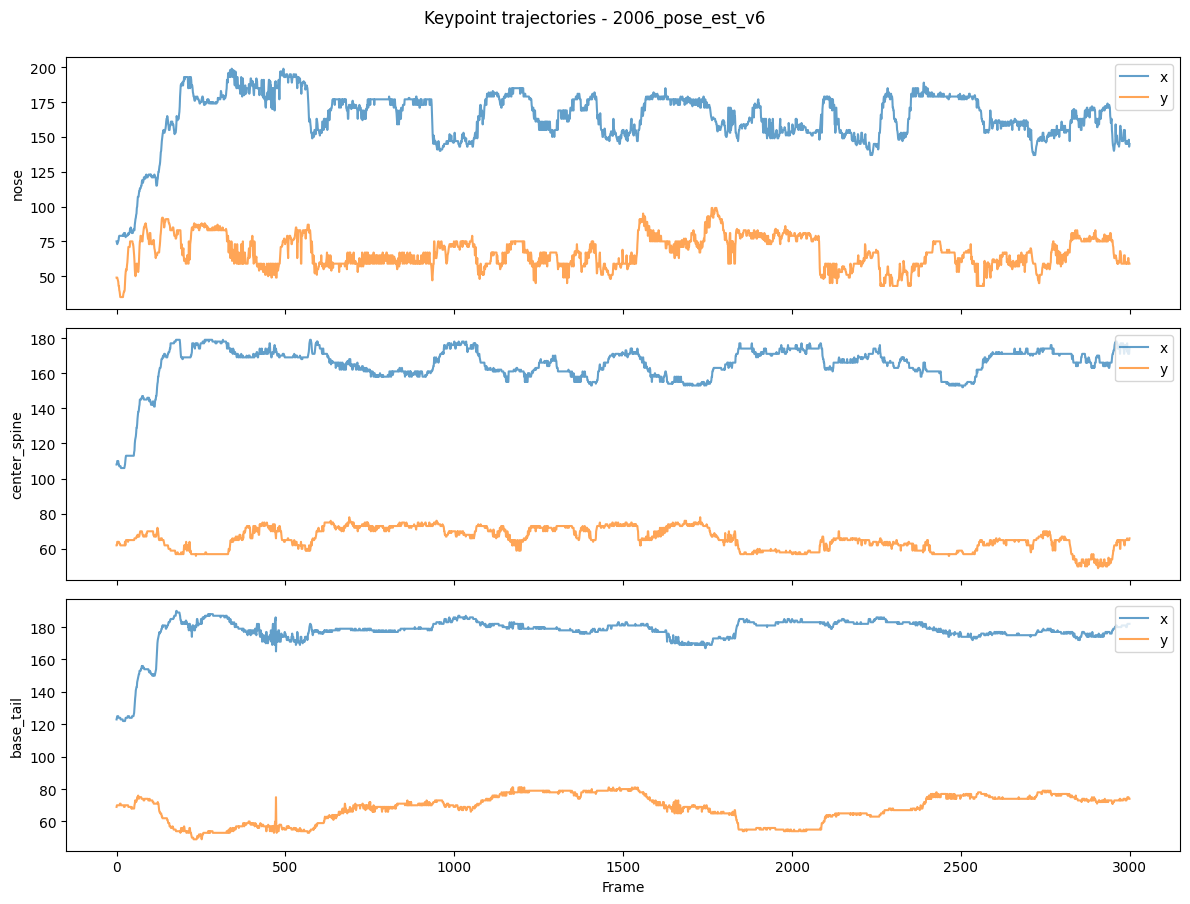

In [6]:
# Why: see how a few representative body parts move over time, before
# looking at all 12 keypoints at once.
parts_to_plot = ["nose", "center_spine", "base_tail"]
fig, axes = plt.subplots(len(parts_to_plot), 1,
                         figsize=(12, 3 * len(parts_to_plot)), sharex=True)

for ax, part in zip(axes, parts_to_plot):
    subset = pose_df[pose_df["body_part"] == part]
    ax.plot(subset["frame"], subset["x"], label="x", alpha=0.7)
    ax.plot(subset["frame"], subset["y"], label="y", alpha=0.7)
    ax.set_ylabel(part)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Frame")
fig.suptitle(f"Keypoint trajectories - {pose_path.stem}", y=1.0)
plt.tight_layout()
plt.show()

Each panel shows how one body part moves (in pixel coordinates) across the first 3,000 frames. The x and y traces shift together during locomotion as the mouse crosses the arena. Abrupt jumps in a single coordinate while the other stays flat are usually detection errors rather than real movement. Notice that the tail tends to track the spine with a short lag and show smoother motion - it is a larger target and easier for the model to localize than the rapidly-moving nose.

> **QC note:** Session `2001` - the very first file in this dataset - has both the
> lowest mean confidence and among the least frame-to-frame movement of all 25 grooming
> sessions. That combination is a reasonable trigger to go pull up `2001.avi` and watch it:
> is the mouse actually just still, or is the pose model losing track of it? We do not chase
> that down here, but it is exactly the kind of discrepancy this workflow is built to catch,
> and it is why the walkthrough below uses a different session as its running example.


## Visualize the Pose on One Frame

Pick the frame with the highest mean confidence and draw the 12 keypoints as a skeleton. Image coordinates put (0, 0) at the top-left, so we invert the y axis.

A **skeleton** is the set of line segments connecting adjacent body parts. Drawing segments between anatomically-connected keypoints turns the point cloud into a recognizable mouse shape. The segments below match the `FULL_CONNECTED_SEGMENTS` chains defined in the JABS package (`jabs.core.abstract.pose_est.PoseEstimation`).

In [7]:
# Why: turn the JABS chain definition into (start, end) keypoint pairs once, so
# every skeleton plot below can reuse it.
# Build skeleton edges from the JABS package chain definition.
#
# PoseEstimation.FULL_CONNECTED_SEGMENTS is a list of chains. Each chain is a
# sequence of keypoint indices connected in order - like beads on a string.
# We convert each consecutive pair within a chain into a named (start, end) edge.
#
# Printing both the raw chains and the final edge list lets you verify the
# skeleton matches the anatomy you expect before any plotting happens.

print("FULL_CONNECTED_SEGMENTS chains:")
for i, chain in enumerate(PoseEstimation.FULL_CONNECTED_SEGMENTS):
    chain_str = " -> ".join(KEYPOINT_NAMES[int(k)] for k in chain)
    print(f"  chain {i}: {chain_str}")

SKELETON_EDGES = [
    (KEYPOINT_NAMES[int(s)], KEYPOINT_NAMES[int(e)])
    for chain in PoseEstimation.FULL_CONNECTED_SEGMENTS
    for s, e in zip(chain, chain[1:])
]

print(f"\nSKELETON_EDGES ({len(SKELETON_EDGES)} edges):")
for src, dst in SKELETON_EDGES:
    print(f"  {src:20s} -> {dst}")

FULL_CONNECTED_SEGMENTS chains:
  chain 0: left_front_paw -> center_spine -> right_front_paw
  chain 1: left_rear_paw -> base_tail -> right_rear_paw
  chain 2: nose -> base_neck -> center_spine -> base_tail -> mid_tail -> tip_tail
  chain 3: left_ear -> nose -> right_ear

SKELETON_EDGES (11 edges):
  left_front_paw       -> center_spine
  center_spine         -> right_front_paw
  left_rear_paw        -> base_tail
  base_tail            -> right_rear_paw
  nose                 -> base_neck
  base_neck            -> center_spine
  center_spine         -> base_tail
  base_tail            -> mid_tail
  mid_tail             -> tip_tail
  left_ear             -> nose
  nose                 -> right_ear


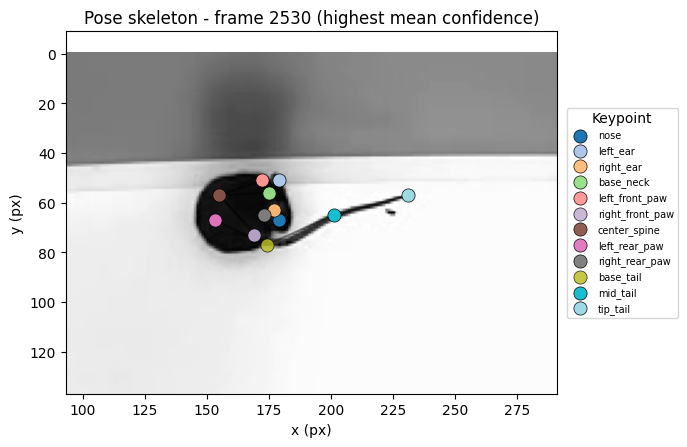

In [8]:
# Why: draw the single highest-confidence frame as a skeleton over the
# real video frame, so keypoint placement can be checked visually
# against the actual mouse rather than trusted blindly.
# Use the frame with the highest mean keypoint confidence.
best_frame = pose_df.groupby("frame")["confidence"].mean().idxmax()
frame_data = pose_df[pose_df["frame"] == best_frame].set_index("body_part")

# Draw the corresponding video frame behind the skeleton so the points can be
# checked against the actual mouse, not just against each other.
# Pose files are named {session}_pose_est_v6.h5; videos are {session}.avi -
# strip the _pose_est_v6 suffix rather than just swapping the file extension.
video_path = pose_path.parent / (pose_path.name.split("_pose_est")[0] + ".avi")
frame_img = None
if video_path.exists():
    cap = cv2.VideoCapture(str(video_path))
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(best_frame))
    ok, frame_bgr = cap.read()
    cap.release()
    if ok:
        frame_img = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(figsize=(7.5, 6))
if frame_img is not None:
    ax.imshow(frame_img)
    # Crop the view to the mouse (plus a margin) instead of showing the
    # whole arena - the animal is a small fraction of the frame otherwise.
    pad = 60
    x_min, x_max = frame_data["x"].min() - pad, frame_data["x"].max() + pad
    y_min, y_max = frame_data["y"].min() - pad, frame_data["y"].max() + pad
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_max, y_min)  # larger value first: keep the image's downward-y orientation
# Draw skeleton edges first so keypoint dots sit on top.
for start, end in SKELETON_EDGES:
    if start in frame_data.index and end in frame_data.index:
        ax.plot(
            [frame_data.loc[start, "x"], frame_data.loc[end, "x"]],
            [frame_data.loc[start, "y"], frame_data.loc[end, "y"]],
            "k-", alpha=0.4, linewidth=1.5,
        )

# Color each keypoint distinctly (via a legend) instead of labeling points
# in-place - with 12 keypoints packed onto a small, cropped mouse body,
# inline text labels overlap each other and become unreadable.
kp_colors = plt.get_cmap("tab20")(np.linspace(0, 1, len(KEYPOINT_NAMES)))
color_by_kp = dict(zip(KEYPOINT_NAMES, kp_colors))

# Scale point opacity to confidence so low-confidence keypoints appear faint.
for kp_name, row in frame_data.iterrows():
    alpha = float(np.clip(row["confidence"], 0.2, 1.0))
    ax.scatter(row["x"], row["y"], s=90, alpha=alpha, zorder=5,
               color=color_by_kp[kp_name], edgecolor="black", linewidth=0.5,
               label=kp_name)

ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=7,
          title="Keypoint", borderaxespad=0)

ax.set_title(f"Pose skeleton - frame {best_frame} (highest mean confidence)")
ax.set_aspect("equal")
if frame_img is None:
    ax.invert_yaxis()  # no frame to anchor to; still flip to the image convention
ax.set_xlabel("x (px)")
ax.set_ylabel("y (px)")
fig.subplots_adjust(right=0.78)
plt.show()

The skeleton overlays 11 segments on the mouse for the single highest-quality frame. The source video frame is drawn behind the skeleton (when the video file is available) and cropped to the mouse so you can check the points against the actual animal, not the whole arena. Each keypoint is colored distinctly and identified in the legend rather than labeled in place - the 12 points are too close together on a cropped mouse for inline text to stay readable. Points with lower confidence appear more transparent. The axes are in pixels; `invert_yaxis()` corrects for the image convention where y=0 is the top of the frame. A compact, bilaterally symmetric skeleton with all 12 points tightly clustered is a sign the model is performing well on this frame.

## Keypoint Confidence

How confident the model is per body part, and how mean confidence varies over the whole session. This previews the quality-control step covered on the Precomputed Tracking & QC page.

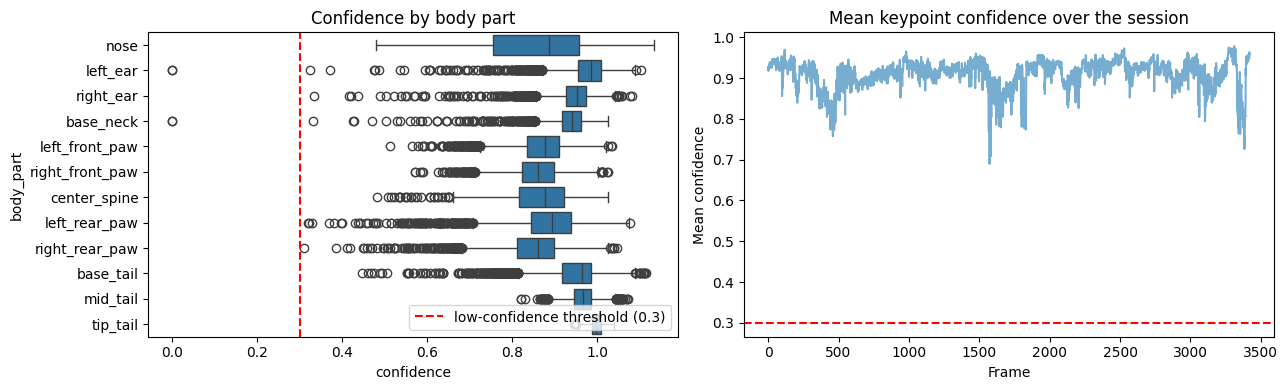

In [9]:
# Why: compare confidence across body parts and across time, to see
# which keypoints or periods of the session are least trustworthy.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: confidence distribution by body part (exploratory window).
sns.boxplot(data=pose_df, x="confidence", y="body_part", ax=axes[0])
axes[0].axvline(0.3, color="red", linestyle="--", label="low-confidence threshold (0.3)")
axes[0].set_title("Confidence by body part")
axes[0].legend(loc="lower right")

# Right: mean confidence over the full session (all frames, not just the window).
mean_conf_per_frame = confidence.mean(axis=1)
axes[1].plot(np.arange(n_frames), mean_conf_per_frame, alpha=0.6)
axes[1].axhline(0.3, color="red", linestyle="--")
axes[1].set_xlabel("Frame")
axes[1].set_ylabel("Mean confidence")
axes[1].set_title("Mean keypoint confidence over the session")

plt.tight_layout()
plt.show()

**Left:** tail keypoints (mid_tail, tip_tail) consistently score lower than head and spine keypoints. The tail is thin, flexible, and often partially occluded by the body, which makes it harder for the model to localize. **Right:** mean confidence over the session stays well above the 0.3 threshold for most frames - occasional dips correspond to rapid movement or brief occlusion. Precomputed Tracking & QC will use this confidence signal for quality-control filtering.

## Session Metadata

The grooming project does not carry strain or sex fields - sessions are identified by numeric JAX colony animal IDs (`2001`, `2022`, etc.). What the project does document is **annotation coverage**: how many frames each session spans, and how many were labeled. We read that directly from the JABS annotation JSON files alongside each pose file.

In [10]:
# Why: summarize frame count, mean confidence, and annotation coverage
# for every session in the dataset, not just the one opened above.
# Annotation files live in jabs/annotations/ relative to the pose files.
# For the toy sample this directory may not exist; handle gracefully.
ann_dir = data_dir / "jabs" / "annotations"


def read_annotation_coverage(session_id: str) -> dict:
    """Read annotation coverage stats from a JABS annotation JSON.

    Args:
        session_id: Session identifier, used as the annotation file stem.

    Returns:
        A dict with "annotated" (bool), "n_labeled_frames" (int) and
        "n_grooming_frames" (int). All values are False / 0 if the annotation
        file does not exist.
    """
    path = ann_dir / f"{session_id}.json"
    if not path.exists():
        return {"annotated": False, "n_labeled_frames": 0, "n_grooming_frames": 0}
    ann = json.loads(path.read_text(encoding="utf-8"))
    # Sum frames where the grooming behavior was labeled as present.
    n_grooming = 0
    for identity_labels in ann.get("unfragmented_labels", {}).values():
        for bout in identity_labels.get("grooming", []):
            if bout.get("present"):
                n_grooming += bout["end"] - bout["start"] + 1
    return {
        "annotated": True,
        "n_labeled_frames": ann.get("num_frames", 0),
        "n_grooming_frames": n_grooming,
    }


records = []
for pf in pose_files:
    # Strip pose suffix to recover the session ID used in annotation filenames.
    session_id = pf.stem.split("_pose_est")[0]
    with h5py.File(str(pf), "r") as f:
        n         = f["poseest/points"].shape[0]
        mean_conf = float(f["poseest/confidence"][:].mean())
    coverage = read_annotation_coverage(session_id)
    records.append({
        "session":           session_id,
        "n_frames":          n,
        "mean_confidence":   round(mean_conf, 3),
        "annotated":         coverage["annotated"],
        "n_labeled_frames":  coverage["n_labeled_frames"],
        "n_grooming_frames": coverage["n_grooming_frames"],
    })

metadata_df = pd.DataFrame(records)
print(f"Sessions: {len(metadata_df)}")
print(f"Annotated: {metadata_df['annotated'].sum()} / {len(metadata_df)}")
metadata_df

Sessions: 25
Annotated: 17 / 25


,session,n_frames,mean_confidence,annotated,n_labeled_frames,n_grooming_frames
0,2001,2469,0.866,True,2469,2091
1,2002,2298,0.911,False,0,0
2,2003,2636,0.921,False,0,0
3,2004,996,0.939,True,996,0
4,2005,1548,0.932,True,1548,0
5,2006,3421,0.910,False,0,0
6,2007,10788,0.958,True,10788,378
7,2008,614,0.960,False,0,0
8,2009,912,0.923,True,912,535
9,2010,1491,0.925,True,1491,749


`n_frames` is the total clip length (9,000 frames = 5 minutes at 30 fps for the full Zenodo data). `n_labeled_frames` is how many frames an annotator reviewed; `n_grooming_frames` is the subset where grooming was marked as present. The ratio `n_grooming_frames / n_labeled_frames` is the **prevalence** of grooming in each session - this distribution matters when training the classifier. Sessions from the toy sample show `annotated=False` because the toy data is pose-only.

## Understanding Checkpoint

Before moving on, make sure you can answer these in your own words:

1. Why does keypoint position being stored as `[y, x]` (not `[x, y]`) matter when you plot it?
2. The pose file has an "animal" axis of size 1. Why is it there, and why do we index `[:, 0, ...]`?
3. Looking at the session metadata table: what does `n_labeled_frames` represent, and why might it differ from `n_frames`?

## Challenge Questions

- Compare the confidence distribution of the tail keypoints against the nose. Why might one body part consistently have lower confidence than another, and what does that imply for downstream analysis?
- The exploratory table is limited to the first `max_frames_explore` frames. What changes in the trajectory and confidence plots if you raise it to the full session? What is the cost?
- The grooming project does not include strain metadata. What additional data source would you need to add strain information to the session table, and where would you find it? (Hint: see [the Dataverse deep dive](deep_dive_dataverse.html).)

## What Next

You loaded real pose data, inspected the HDF5 schema, extracted keypoints, and visualized trajectories, a skeleton, and confidence.

**Next:** Precomputed Tracking & QC works with pre-computed tracking across many sessions at once. If you want to go deeper on how these keypoints are actually produced from raw video, see the Pose Estimation deep dive.
